<a href="https://colab.research.google.com/github/suma-2114/PowerBIAssignment1/blob/main/Capstone_Project(Netflix).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [6]:
df = pd.read_csv("/combined_data_1.txt",header=None, names=['Cust_ID','Rating'],usecols=[0,1])

In [7]:
df

,Cust_ID,Rating
0,1:,NaN
1,1488844,3.0
2,822109,5.0
3,885013,4.0
4,30878,4.0
...,...,...
254783,2013338,4.0
254784,9964,4.0
254785,286568,4.0
254786,2174151,4.0


In [8]:
df.isnull().sum()

,0
Cust_ID,0
Rating,55


In [9]:
movie_count=df.isnull().sum()
movie_count=movie_count['Rating']
movie_count

np.int64(55)

In [10]:
total_count=df['Cust_ID'].nunique()
total_count

171758

In [11]:
customer_count=total_count-movie_count
customer_count

np.int64(171703)

In [12]:
ratings_count=df['Cust_ID'].count()-movie_count
ratings_count

np.int64(254733)

In [13]:
stars=df.groupby('Rating').agg(['count'])

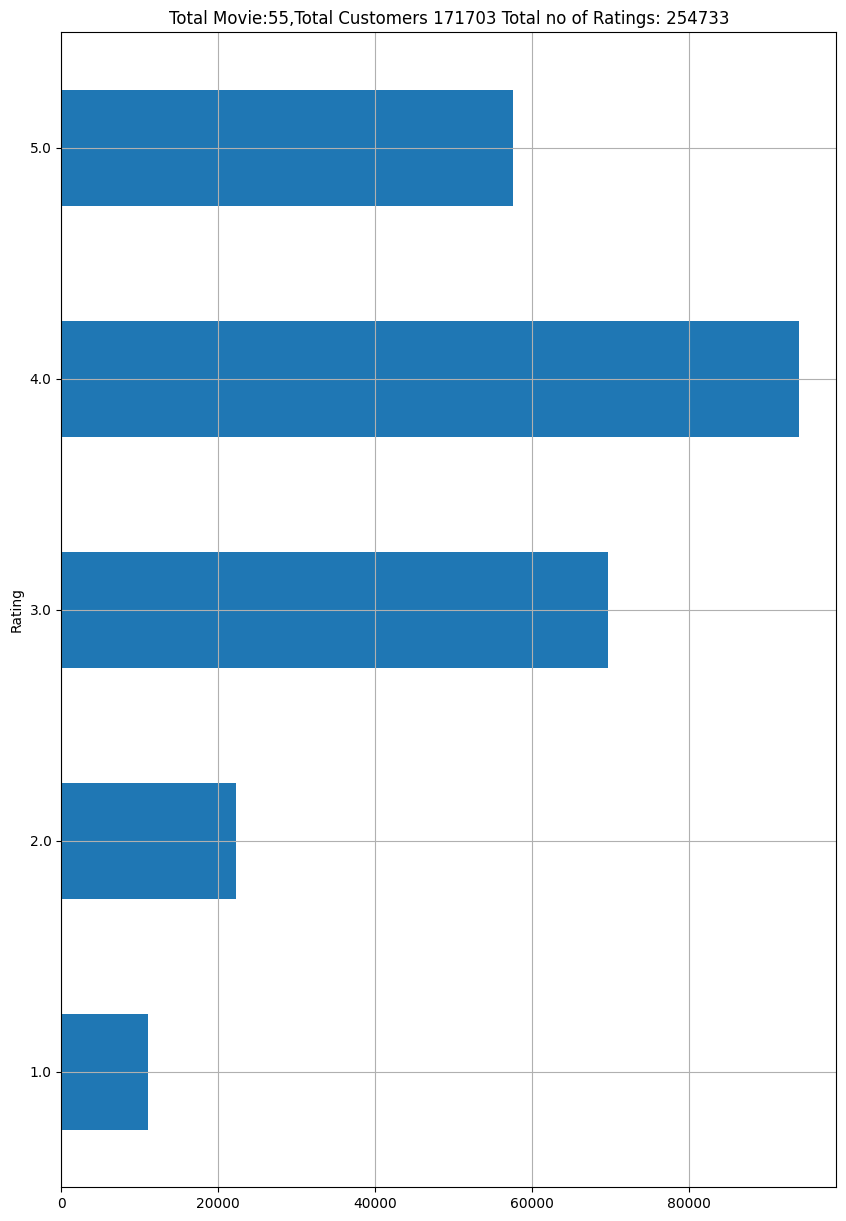

In [14]:
ax=stars.plot(kind='barh',legend=False,figsize=(10,15))
plt.title(f'Total Movie:{movie_count},Total Customers {customer_count} Total no of Ratings: {ratings_count}')
plt.grid(True)
plt.show()

In [15]:
#Let's just make a clear dataframe to find how many movie id are there

movie_id=None
movie_np=[]   #Empty List to store all movie id

#Iterate over the dataframe rows
for i in df['Cust_ID']:
  if ':' in i:
    #Udpate the current movie id in  column
    movie_id=int(i.replace(':',""))
  movie_np.append(movie_id)

In [16]:
movie_np

[1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,


In [17]:
#Create a new column in dataset to store movie id
df['Movie_Id']=movie_np

In [18]:
df

,Cust_ID,Rating,Movie_Id
0,1:,NaN,1
1,1488844,3.0,1
2,822109,5.0,1
3,885013,4.0,1
4,30878,4.0,1
...,...,...,...
254783,2013338,4.0,55
254784,9964,4.0,55
254785,286568,4.0,55
254786,2174151,4.0,55


In [19]:
#To keep only the rows where the ratings ccolumn is not null
df=df[df['Rating'].notna()]

In [20]:
df

,Cust_ID,Rating,Movie_Id
1,1488844,3.0,1
2,822109,5.0,1
3,885013,4.0,1
4,30878,4.0,1
5,823519,3.0,1
...,...,...,...
254783,2013338,4.0,55
254784,9964,4.0,55
254785,286568,4.0,55
254786,2174151,4.0,55


In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 254733 entries, 1 to 254787
Data columns (total 3 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   Cust_ID   254733 non-null  object 
 1   Rating    254733 non-null  float64
 2   Movie_Id  254733 non-null  int64  
dtypes: float64(1), int64(1), object(1)
memory usage: 7.8+ MB


In [22]:
df['Cust_ID']=df['Cust_ID'].astype(int)

/tmp/ipykernel_1808/545653006.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Cust_ID']=df['Cust_ID'].astype(int)


In [23]:
#pre filtering:
#remove all the users that have rated the less movies
#remove all the movies that have been rated less

In [24]:
#count the ratings of movie id
movie_summary=df.groupby('Movie_Id')['Rating'].agg(['count'])

In [25]:
movie_summary


,count
Movie_Id,
1,547
2,145
3,2012
4,142
5,1140
6,1019
7,93
8,14910
9,95


In [26]:
#Now we will create a benchmark
movie_benchmark=round(movie_summary['count'].quantile(0.6),0)
movie_benchmark

np.float64(817.0)

In [27]:
#if any movie is rating less than 908 exclude that movie

drop_movie_list=movie_summary[movie_summary['count']<movie_benchmark].index
drop_movie_list

Index([ 1,  2,  4,  7,  9, 10, 11, 12, 13, 14, 15, 19, 20, 21, 22, 23, 27, 29,
       31, 34, 37, 38, 39, 40, 41, 42, 43, 49, 50, 51, 53, 54, 55],
      dtype='int64', name='Movie_Id')

In [28]:
len(drop_movie_list)

33

In [29]:
#remove all the customers that have rated the less movie
cust_summary=df.groupby('Cust_ID')['Rating'].agg(['count'])

In [30]:
cust_summary

,count
Cust_ID,
6,1
7,3
42,1
59,1
79,1
...,...
2649376,1
2649378,2
2649388,1


In [31]:
cust_benchmark=round(cust_summary['count'].quantile(0.6),0)
cust_benchmark

np.float64(1.0)

In [32]:
#If any user have rated less than 36 movie exclude them
drop_cust_list=cust_summary[cust_summary['count']<cust_benchmark].index
drop_cust_list

Index([], dtype='int64', name='Cust_ID')

In [33]:
#How many users we are removing
len(drop_cust_list)

0

In [34]:
df=df[~df['Movie_Id'].isin(drop_movie_list)]    #Please consider movie after excluding the movie which are present in this list
df=df[~df['Cust_ID'].isin(drop_cust_list)]    #Please consider movie after excluding the movie which are present in this list

In [35]:
df# Final shape after removing extra  users and less rated movies

,Cust_ID,Rating,Movie_Id
695,1025579,4.0,3
696,712664,5.0,3
697,1331154,4.0,3
698,2632461,3.0,3
699,44937,5.0,3
...,...,...,...
254176,2133893,5.0,52
254177,839632,4.0,52
254178,1591803,5.0,52
254179,1474326,5.0,52


**MODEL BUILDING**

In [37]:
df_title=pd.read_csv('/movies.csv',encoding='ISO-8859-1',header=None,names=['Movie_Id','Year','Name'],usecols=[0,1,2])
df_title

,Movie_Id,Year,Name
0,movieId,title,genres
1,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
2,2,Jumanji (1995),Adventure|Children|Fantasy
3,3,Grumpier Old Men (1995),Comedy|Romance
4,4,Waiting to Exhale (1995),Comedy|Drama|Romance
...,...,...,...
27274,131254,Kein Bund fÃ¼r's Leben (2007),Comedy
27275,131256,"Feuer, Eis & Dosenbier (2002)",Comedy
27276,131258,The Pirates (2014),Adventure
27277,131260,Rentun Ruusu (2001),(no genres listed)


In [38]:
#Install surprise library
!pip install scikit-surprise

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 6.4 MB/s  0:00:00


!pip install numpy==1.26.4
!pip install scikit-surprise --no-cache-dir

In [41]:
from surprise import Reader, Dataset, SVD
from surprise.model_selection import cross_validate

In [42]:
reader=Reader()

In [43]:
data=Dataset.load_from_df(df[['Cust_ID','Movie_Id','Rating']][:100000],reader)

In [44]:
data

In [45]:
model=SVD()

In [46]:
cross_validate(model,data,measures=['RMSE'],cv=3)

{'test_rmse': array([1.04757382, 1.04082936, 1.05208573]),
 'fit_time': (1.7152142524719238, 1.3004848957061768, 2.7755379676818848),
 'test_time': (0.26071643829345703, 0.1478407382965088, 0.3212544918060303)}

In [47]:
# Recommendation

user_rating=df[df['Cust_ID']==1331154]
user_rating

,Cust_ID,Rating,Movie_Id
697,1331154,4.0,3
5178,1331154,4.0,8
31460,1331154,3.0,18
92840,1331154,4.0,30
224761,1331154,3.0,44


In [48]:
user_1331154=df_title.copy()
user_1331154

,Movie_Id,Year,Name
0,movieId,title,genres
1,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
2,2,Jumanji (1995),Adventure|Children|Fantasy
3,3,Grumpier Old Men (1995),Comedy|Romance
4,4,Waiting to Exhale (1995),Comedy|Drama|Romance
...,...,...,...
27274,131254,Kein Bund fÃ¼r's Leben (2007),Comedy
27275,131256,"Feuer, Eis & Dosenbier (2002)",Comedy
27276,131258,The Pirates (2014),Adventure
27277,131260,Rentun Ruusu (2001),(no genres listed)


In [49]:
user_1331154=user_1331154[~user_1331154['Movie_Id'].isin(drop_movie_list)]

In [50]:
user_1331154

,Movie_Id,Year,Name
0,movieId,title,genres
1,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
2,2,Jumanji (1995),Adventure|Children|Fantasy
3,3,Grumpier Old Men (1995),Comedy|Romance
4,4,Waiting to Exhale (1995),Comedy|Drama|Romance
...,...,...,...
27274,131254,Kein Bund fÃ¼r's Leben (2007),Comedy
27275,131256,"Feuer, Eis & Dosenbier (2002)",Comedy
27276,131258,The Pirates (2014),Adventure
27277,131260,Rentun Ruusu (2001),(no genres listed)


In [51]:
#Prediction Part
user_1331154['Estimated_Rating']=user_1331154['Movie_Id'].apply(lambda x: model.predict(1331154,x).est)

In [52]:
user_1331154

,Movie_Id,Year,Name,Estimated_Rating
0,movieId,title,genres,3.489698
1,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,3.489698
2,2,Jumanji (1995),Adventure|Children|Fantasy,3.489698
3,3,Grumpier Old Men (1995),Comedy|Romance,3.489698
4,4,Waiting to Exhale (1995),Comedy|Drama|Romance,3.489698
...,...,...,...,...
27274,131254,Kein Bund fÃ¼r's Leben (2007),Comedy,3.489698
27275,131256,"Feuer, Eis & Dosenbier (2002)",Comedy,3.489698
27276,131258,The Pirates (2014),Adventure,3.489698
27277,131260,Rentun Ruusu (2001),(no genres listed),3.489698


In [53]:
user_1331154.sort_values('Estimated_Rating',ascending=False)
user_1331154.head(5)

,Movie_Id,Year,Name,Estimated_Rating
0,movieId,title,genres,3.489698
1,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,3.489698
2,2,Jumanji (1995),Adventure|Children|Fantasy,3.489698
3,3,Grumpier Old Men (1995),Comedy|Romance,3.489698
4,4,Waiting to Exhale (1995),Comedy|Drama|Romance,3.489698
